In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("housing.csv")

In [3]:
df.shape

(20640, 10)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [5]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [6]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [7]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


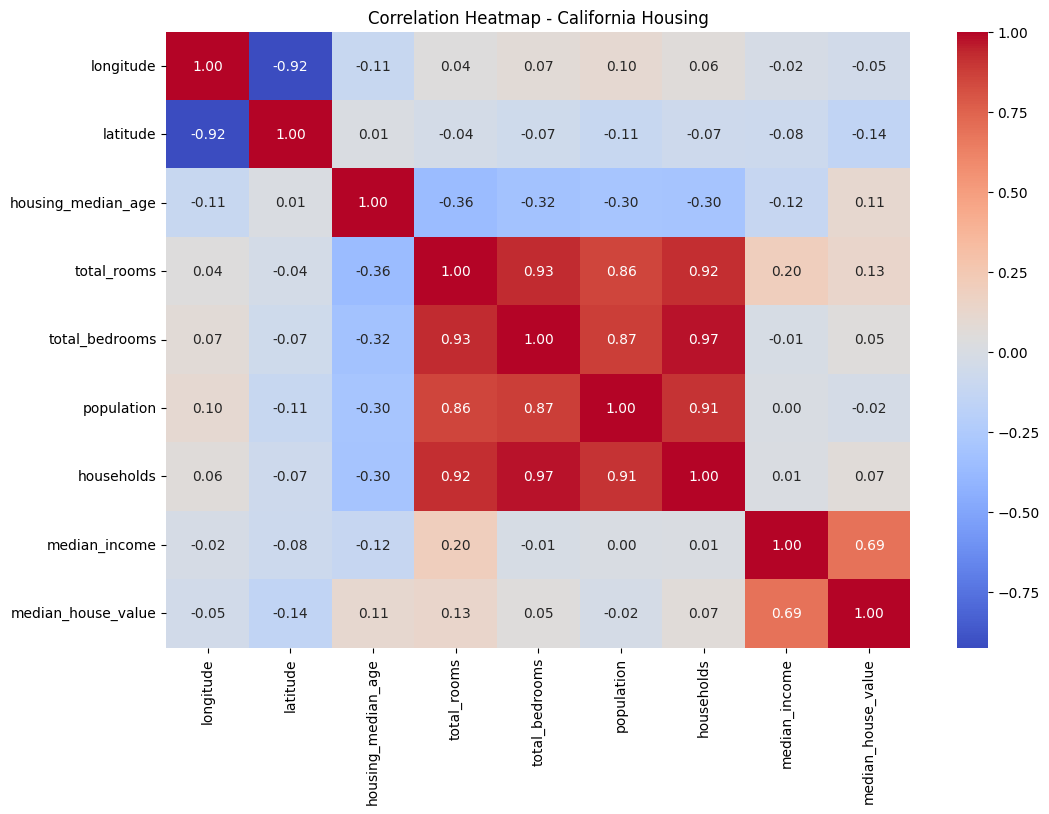

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns only
numerical_df = df.select_dtypes(include="number")

# Calculate correlation
correlation = numerical_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap - California Housing")
plt.show()

In [9]:
df['income_age_interaction'] = df['median_income'] * df['housing_median_age']

In [10]:
df = pd.get_dummies(
    df,
    columns=["ocean_proximity"],
    dtype=int
)

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

X_test, X_train, y_test, y_train = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# 1. OLS Regression
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)

# 2. Ridge Regression (L2)
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

# 3. Lasso Regression (L1)
lasso_model = Lasso(alpha=1.0, max_iter=10000)
lasso_model.fit(X_train_scaled, y_train)

print("All three models trained successfully!")

All three models trained successfully!


In [15]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Predictions on test data
ols_pred = ols_model.predict(X_test_scaled)
ridge_pred = ridge_model.predict(X_test_scaled)
lasso_pred = lasso_model.predict(X_test_scaled)

# Evaluation function
def evaluate_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    }

# Compare all models
results = pd.DataFrame([
    evaluate_model("OLS", y_test, ols_pred),
    evaluate_model("Ridge", y_test, ridge_pred),
    evaluate_model("Lasso", y_test, lasso_pred)
])

print(results.round(3))

   Model       RMSE        MAE  R2 Score
0    OLS  68668.379  49850.185     0.647
1  Ridge  68667.050  49844.704     0.647
2  Lasso  68668.381  49849.980     0.647


In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge, Lasso

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

# Ridge tuning
ridge_grid = GridSearchCV(
    Ridge(),
    {"alpha": alpha_values},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(X_train_scaled, y_train)

# Lasso tuning
lasso_grid = GridSearchCV(
    Lasso(max_iter=10000),
    {"alpha": alpha_values},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_grid.fit(X_train_scaled, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_["alpha"])
print("Best Ridge CV RMSE:", -ridge_grid.best_score_)

print("Best Lasso alpha:", lasso_grid.best_params_["alpha"])
print("Best Lasso CV RMSE:", -lasso_grid.best_score_)

Best Ridge alpha: 10
Best Ridge CV RMSE: 70393.67398789385
Best Lasso alpha: 100
Best Lasso CV RMSE: 70443.3716598122


In [17]:
# Predictions using tuned models
ridge_tuned_pred = ridge_grid.best_estimator_.predict(X_test_scaled)
lasso_tuned_pred = lasso_grid.best_estimator_.predict(X_test_scaled)

# Evaluate tuned models
tuned_results = pd.DataFrame([
    evaluate_model("Ridge Tuned", y_test, ridge_tuned_pred),
    evaluate_model("Lasso Tuned", y_test, lasso_tuned_pred)
])

print(tuned_results.round(3))

         Model       RMSE        MAE  R2 Score
0  Ridge Tuned  68665.340  49808.539     0.647
1  Lasso Tuned  68675.632  49834.308     0.647


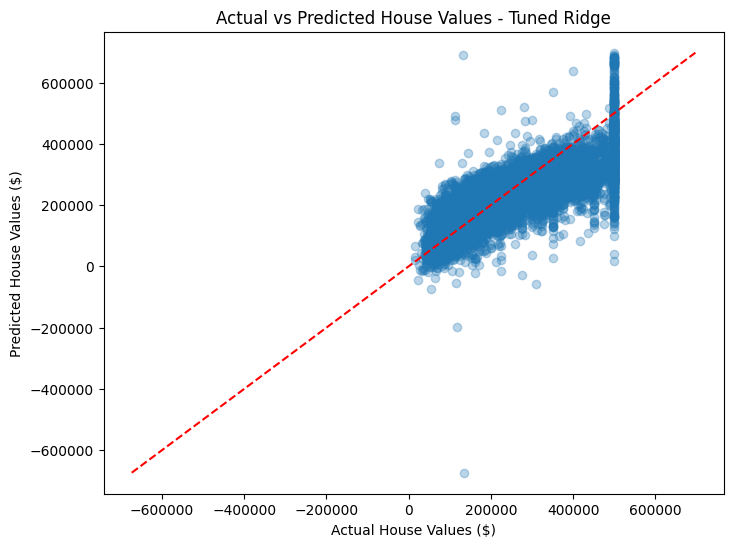

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, ridge_tuned_pred, alpha=0.3)

# Perfect prediction reference line
min_value = min(y_test.min(), ridge_tuned_pred.min())
max_value = max(y_test.max(), ridge_tuned_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual House Values ($)")
plt.ylabel("Predicted House Values ($)")
plt.title("Actual vs Predicted House Values - Tuned Ridge")
plt.show()

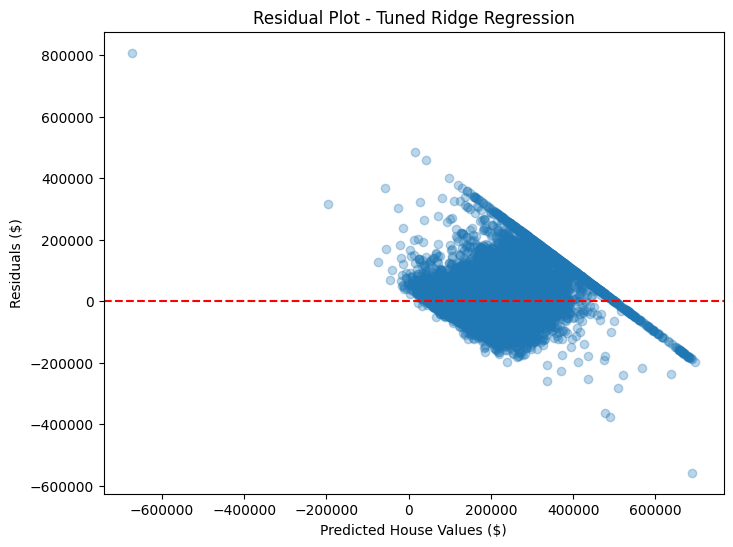

In [19]:
# Calculate residuals
residuals = y_test - ridge_tuned_pred

plt.figure(figsize=(8, 6))
plt.scatter(ridge_tuned_pred, residuals, alpha=0.3)

# Zero-error reference line
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Values ($)")
plt.ylabel("Residuals ($)")
plt.title("Residual Plot - Tuned Ridge Regression")
plt.show()

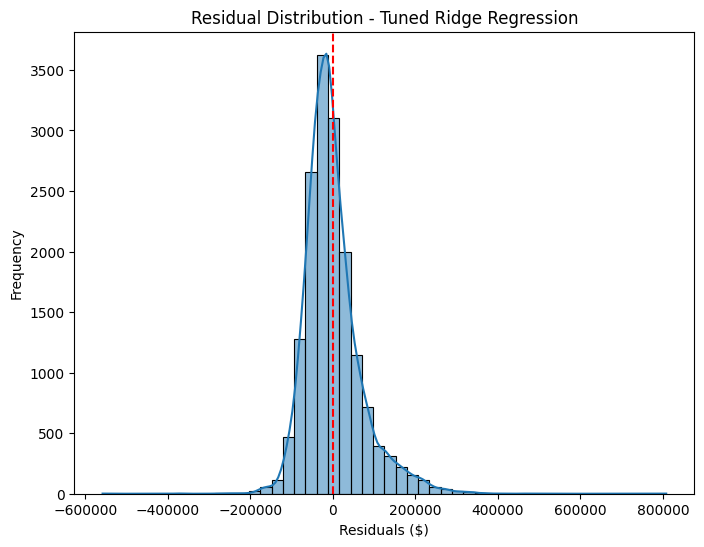

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

residuals = y_test - ridge_tuned_pred

plt.figure(figsize=(8, 6))

sns.histplot(residuals, bins=50, kde=True)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Residuals ($)")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Tuned Ridge Regression")

plt.show()